In [1]:
#10.10 상대적 위치 편향 계산
import torch

window_size = 2
coords_h = torch.arange(window_size)
coords_w = torch.arange(window_size)
coords = torch.stack(torch.meshgrid([coords_h, coords_w], indexing="ij"))
coords_flatten = torch.flatten(coords, 1)
relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]
print(relative_coords)
print(relative_coords.shape)

tensor([[[ 0,  0, -1, -1],
         [ 0,  0, -1, -1],
         [ 1,  1,  0,  0],
         [ 1,  1,  0,  0]],

        [[ 0, -1,  0, -1],
         [ 1,  0,  1,  0],
         [ 0, -1,  0, -1],
         [ 1,  0,  1,  0]]])
torch.Size([2, 4, 4])


In [2]:
#10.11 X, Y축에 대한 위치 행렬
x_coords = relative_coords[0, :, :]
y_coords = relative_coords[1, :, :]

x_coords += window_size -1
y_coords += window_size -1
x_coords *= 2 * window_size -1
print(f"X축에 대한 행렬:\n{x_coords}\n")
print(f"Y축에 대한 행렬:\n{y_coords}\n")
relative_position_index = x_coords + y_coords
print(f"X, Y축에 대한 위치 행렬: \n{relative_position_index}")

X축에 대한 행렬:
tensor([[3, 3, 0, 0],
        [3, 3, 0, 0],
        [6, 6, 3, 3],
        [6, 6, 3, 3]])

Y축에 대한 행렬:
tensor([[1, 0, 1, 0],
        [2, 1, 2, 1],
        [1, 0, 1, 0],
        [2, 1, 2, 1]])

X, Y축에 대한 위치 행렬: 
tensor([[4, 3, 1, 0],
        [5, 4, 2, 1],
        [7, 6, 4, 3],
        [8, 7, 5, 4]])


In [3]:
#10.12 X축 Y축에 대한 상대적 위치 좌표 변환
num_heads = 1
relative_position_bias_table = torch.Tensor(
    torch.zeros(
        (2 * window_size - 1) * (2 * window_size - 1), num_heads
    )
)
relative_position_bias = relative_position_bias_table[relative_position_index.view(-1)]
relative_position_bias = relative_position_bias.view(
    window_size * window_size, window_size * window_size, -1
)
print(relative_position_bias.shape)

torch.Size([4, 4, 1])


In [4]:
#10.1
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets

def subset_sampler(dataset, classes, max_len):
    # 1, 2번 수정: target_idx 선언 오타 수정 및 enumerate 올바르게 수정
    target_idx = defaultdict(list)
    for idx, (_, label) in enumerate(dataset):
        target_idx[int(label)].append(idx)

    # 3번 수정: 깔끔한 리스트 컴프리헨션
    indices = list(
        chain.from_iterable(
            [target_idx[idx][:max_len] for idx in range(len(classes))]
        )
    )
    return Subset(dataset, indices)

# 데이터셋 다운로드
train_dataset = datasets.FashionMNIST(root="./datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="./datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print("Classes:", classes)
print("Class to Index:", class_to_idx)

# Train 및 Test Subset 생성
subset_train_dataset = subset_sampler(
    dataset=train_dataset, classes=train_dataset.classes, max_len=100
)
# 4번 수정: 테스트 셋에도 샘플러 적용
subset_test_dataset = subset_sampler(
    dataset=test_dataset, classes=test_dataset.classes, max_len=100
)

print(f"Training Data Size: {len(subset_train_dataset)}")
print(f"Testing Data Size: {len(subset_test_dataset)}")
print("First train data sample (Image tensor, Label):", train_dataset[0])

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 208kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.88MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.6MB/s]


Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Class to Index: {'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}
Training Data Size: 1000
Testing Data Size: 1000
First train data sample (Image tensor, Label): (<PIL.Image.Image image mode=L size=28x28 at 0x7891D34B74D0>, 9)


In [5]:
# 10.2 이미지 전처리
import torch
from torchvision import transforms
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path = "google/vit-base-patch16-224-in21k"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size = (
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean = image_processor.image_mean,
            std = image_processor.image_std
        )
    ]
)

print(f"size: {image_processor.size}")
print(f"mean: {image_processor.image_mean}")
print(f"std: {image_processor.image_std}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
mean: (0.5, 0.5, 0.5)
std: (0.5, 0.5, 0.5)


In [6]:
# 10.3 VIT 데이터로더 적용
from torch.utils.data import DataLoader

def collator(data, transform):
  images, labels = zip(*data)
  pixel_values = torch.stack([transform(image) for image in images])
  labels = torch.tensor([label for label in labels])
  return {"pixel_values": pixel_values, "labels": labels}

train_dataloader = DataLoader(
    subset_train_dataset,
    batch_size = 32,
    shuffle = True,
    collate_fn = lambda x: collator(x, transform),
    drop_last = True
)
valid_dataloader = DataLoader(
    subset_test_dataset,
    batch_size = 4,
    shuffle = True,
    collate_fn = lambda x: collator(x, transform),
    drop_last = True
)

batch = next(iter(train_dataloader))
for key, value in batch.items():
  print(f"{key}: {value.shape}")

pixel_values: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])


In [7]:
#10.13 사전 학습된 스윈 트랜스포머 모델
from transformers import SwinForImageClassification

model = SwinForImageClassification.from_pretrained(
    pretrained_model_name_or_path="microsoft/swin-tiny-patch4-window7-224",
    num_labels=len(train_dataset.classes),
    id2label={idx: label for label, idx in train_dataset.class_to_idx.items()},
    label2id=train_dataset.class_to_idx,
    ignore_mismatched_sizes=True,
)

for main_name, main_module in model.named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("└", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("| └", ssub_name)
      for sssub_name, sssub_module in ssub_module.named_children():
        if sssub_name == "projection":
          print("| | └", sssub_name, sssub_module)
        else:
          print("| | └", sssub_name)



config.json:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  113MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


swin
└ embeddings
| └ patch_embeddings
| | └ projection Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
| └ norm
| └ dropout
└ encoder
| └ layers
| | └ 0
| | └ 1
| | └ 2
| | └ 3
└ layernorm
└ pooler
classifier


In [8]:
#10.14 패치 임베딩 모듈
batch = next(iter(train_dataloader))
print("이미지 차원:", batch["pixel_values"].shape)

patch_emb_output, shape = model.swin.embeddings.patch_embeddings(batch["pixel_values"])
print("모듈:", model.swin.embeddings.patch_embeddings)
print("패치 임베딩 차원:", patch_emb_output.shape)

이미지 차원: torch.Size([32, 3, 224, 224])
모듈: SwinPatchEmbeddings(
  (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
)
패치 임베딩 차원: torch.Size([32, 3136, 96])


In [9]:
#10.15 스윈트랜스포머 블록
for main_name, main_module in model.swin.encoder.layers[0].named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("└", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("|└", ssub_name)

blocks
└ 0
|└ attention
|└ layernorm_before
|└ layernorm_after
|└ mlp
|└ dropout
|└ drop_path
└ 1
|└ attention
|└ layernorm_before
|└ layernorm_after
|└ mlp
|└ dropout
|└ drop_path
downsample
└ reduction
└ norm


In [10]:
#10.16 SwinLayer 구조
print(model.swin.encoder.layers[0].blocks[0])

SwinLayer(
  (attention): SwinAttention(
    (q_proj): Linear(in_features=96, out_features=96, bias=True)
    (k_proj): Linear(in_features=96, out_features=96, bias=True)
    (v_proj): Linear(in_features=96, out_features=96, bias=True)
    (o_proj): Linear(in_features=96, out_features=96, bias=True)
    (relative_position_bias): SwinRelativePositionBias()
  )
  (layernorm_before): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  (layernorm_after): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  (mlp): SwinMLP(
    (activation_fn): GELUActivation()
    (fc1): Linear(in_features=96, out_features=384, bias=True)
    (fc2): Linear(in_features=384, out_features=96, bias=True)
  )
  (dropout): Dropout(p=0.0, inplace=False)
  (drop_path): Identity()
)


In [11]:
#10.17 W-MSA, SW-MSA 모듈
print("패치 임베딩 차원:", patch_emb_output.shape)

W_MSA = model.swin.encoder.layers[0].blocks[0]
SW_MSA = model.swin.encoder.layers[0].blocks[1]

W_MSA_output = W_MSA(patch_emb_output, W_MSA.input_resolution)[0]
SW_MSA_output = SW_MSA(W_MSA_output, SW_MSA.input_resolution)[0]

print("W-MSA 결과 차원:", W_MSA_output.shape)
print("SW-MSA 결과 차원:", SW_MSA_output.shape)

패치 임베딩 차원: torch.Size([32, 3136, 96])
W-MSA 결과 차원: torch.Size([32, 3136, 96])
SW-MSA 결과 차원: torch.Size([32, 3136, 96])


In [12]:
#10.18 패치 병합
patch_merge = model.swin.encoder.layers[0].downsample
print("patch_merge 모듈: ", patch_merge)

output = patch_merge(SW_MSA_output, (56, 56))
print("patch_merge 결과 차원 :", output.shape)

patch_merge 모듈:  SwinPatchMerging(
  (reduction): Linear(in_features=384, out_features=192, bias=False)
  (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
)
patch_merge 결과 차원 : torch.Size([32, 784, 192])


In [13]:
!pip install evaluate

In [14]:
#10.19 스윈 트랜스포머 모델 학습
import torch
import evaluate
import numpy as np
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets
from torchvision import transforms
from transformers import AutoImageProcessor
from transformers import SwinForImageClassification
from transformers import TrainingArguments
from transformers import Trainer


def subset_sampler(dataset, classes, max_len):
    target_idx = defaultdict(list)
    for idx, label in enumerate(dataset.targets):
        target_idx[int(label)].append(idx)

    indices = list(
        chain.from_iterable(
            [target_idx[idx][:max_len] for idx in range(len(classes))]
        )
    )
    return Subset(dataset, indices)


def model_init(classes, class_to_idx):
    model = SwinForImageClassification.from_pretrained(
        pretrained_model_name_or_path="microsoft/swin-tiny-patch4-window7-224",
        num_labels=len(classes),
        id2label={idx: label for label, idx in class_to_idx.items()},
        label2id=class_to_idx,
        ignore_mismatched_sizes = True
    )
    return model


def collator(data, transform):
    images, labels = zip(*data)
    pixel_values = torch.stack([transform(image) for image in images])
    labels = torch.tensor([label for label in labels])
    return {"pixel_values": pixel_values, "labels": labels}


def compute_metrics(eval_pred):
    metric = evaluate.load("f1")
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    macro_f1 = metric.compute(
        predictions=predictions,
        references=labels,
        average="macro",
    )
    return macro_f1


train_dataset = datasets.FashionMNIST(
    root="../datasets", download=True, train=True
)
test_dataset = datasets.FashionMNIST(
    root="../datasets", download=True, train=False
)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

subset_train_dataset = subset_sampler(
    dataset=train_dataset, classes=train_dataset.classes, max_len=1000
)
subset_test_dataset = subset_sampler(
    dataset=test_dataset, classes=test_dataset.classes, max_len=1000
)

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path="microsoft/swin-tiny-patch4-window7-224"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size=(
                image_processor.size["height"],
                image_processor.size["width"],
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean=image_processor.image_mean,
            std=image_processor.image_std
        ),
    ]
)

args = TrainingArguments(
    output_dir = "../models/Swin-FashionMNIST",
    save_strategy = "epoch",
    eval_strategy = "epoch",
    learning_rate = 1e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,
    num_train_epochs = 3,
    weight_decay = 0.001,
    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    remove_unused_columns=False,
    seed = 7
)

trainer = Trainer(
    model_init=lambda _: model_init(classes, class_to_idx),
    args=args,
    train_dataset=subset_train_dataset,
    eval_dataset=subset_test_dataset,
    data_collator=lambda x: collator(x, transform),
    compute_metrics=compute_metrics,
    processing_class=image_processor,
)
trainer.train()

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 216kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.95MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.6MB/s]


preprocessor_config.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['swin.encoder.layers.0.blocks.0.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.k_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.k_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.v_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.v_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.o_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.o_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.relative_position_bias.relative_position_bias_table', 'swin.encoder.layers.0.blocks.0.mlp.fc1.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc1.bias', 'swin.encoder.layers.0.blocks.0.mlp.fc2.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc2.bias', 'swin.encoder.layers.0.blocks.1.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.1.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.1.attention.k_proj.weight', 'swin.encode

TrainOutput(global_step=1875, training_loss=0.3642572224934896, metrics={'train_runtime': 614.0449, 'train_samples_per_second': 48.856, 'train_steps_per_second': 3.054, 'total_flos': 7.4584635826176e+17, 'train_loss': 0.3642572224934896, 'epoch': 3.0})

PredictionOutput(predictions=array([[ 8.357545  , -2.7558544 , -0.14524037, ..., -2.1677165 ,
        -1.7938942 , -2.1309226 ],
       [ 4.5195913 , -0.72009504,  0.616781  , ..., -2.2157903 ,
        -0.6627863 , -3.4404519 ],
       [ 7.4827743 , -3.0374904 , -0.39545938, ..., -1.2435434 ,
         0.34582976, -1.7482946 ],
       ...,
       [-1.0814048 , -2.3983803 , -1.8506404 , ...,  2.3602366 ,
        -3.4357605 ,  8.527473  ],
       [-0.5570225 , -2.963177  , -1.4827665 , ..., -1.2599081 ,
        -1.7879605 ,  8.298823  ],
       [-0.34613457, -3.127839  , -1.7730414 , ...,  0.5127183 ,
        -3.4912503 ,  9.688772  ]], dtype=float32), label_ids=array([0, 0, 0, ..., 9, 9, 9]), metrics={'test_loss': 0.27090030908584595, 'test_f1': 0.9070167566309622, 'test_runtime': 98.054, 'test_samples_per_second': 101.985, 'test_steps_per_second': 6.374})


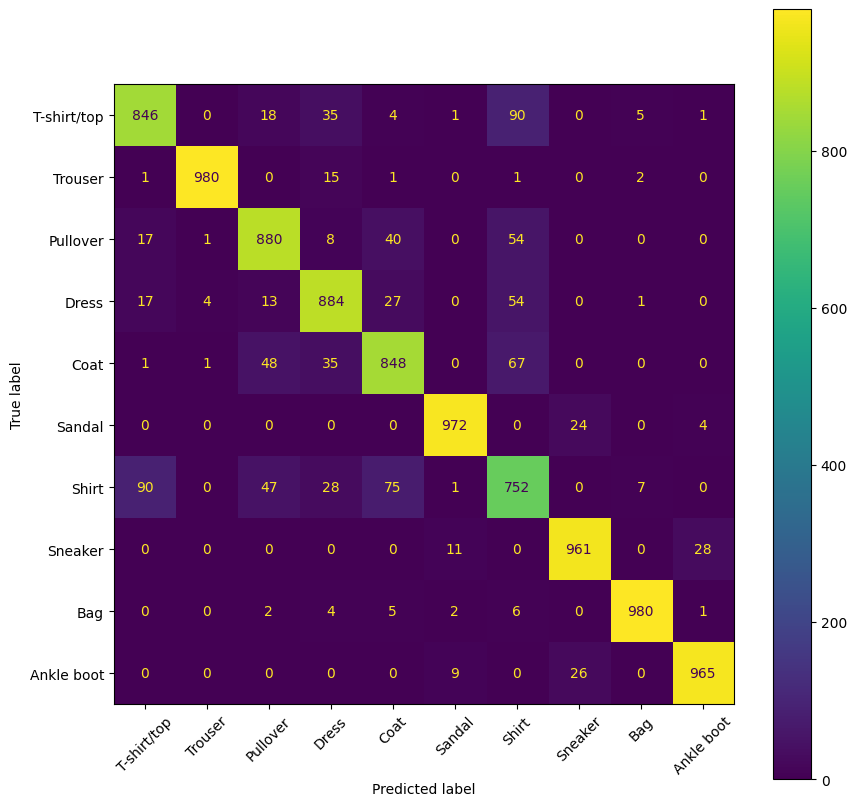

In [15]:
#예제10.9 Swin 모델 성능 평가
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(subset_test_dataset)
print(outputs)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(axis=1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()